In [4]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

In [5]:
p = 100
q = 100
r = 10

U_star = np.random.normal(0,1, size=(p, r))
V_star = np.random.normal(0,1, size=(r, q))

M = U_star @ V_star

In [6]:
# goal: recover U_star and V_star from M
@jax.jit
def loss(U, V):
    M_approx = U @ V
    MSE = jnp.mean((M - M_approx)**2)
    return MSE

loss_grad_U = jax.jit(jax.grad(loss, argnums=0))
loss_grad_V = jax.jit(jax.grad(loss, argnums=1))

In [8]:
# gradient descent initialization
U_init = np.random.normal(0,1, size=(p, r))
V_init = np.random.normal(0,1, size=(r, q))

In [17]:
U_copy = U_init.copy()
V_copy = V_init.copy()

niter = 1000
lr = 1.
loss_history = []

for i in range(niter):
    grad_U = loss_grad_U(U_copy, V_copy)
    grad_V = loss_grad_V(U_copy, V_copy)
    U_copy = U_copy - lr * grad_U
    V_copy = V_copy - lr * grad_V

    current_loss = loss(U_copy, V_copy)
    loss_history.append(current_loss)

    #print(f"Iteration {i}, loss: {current_loss}")

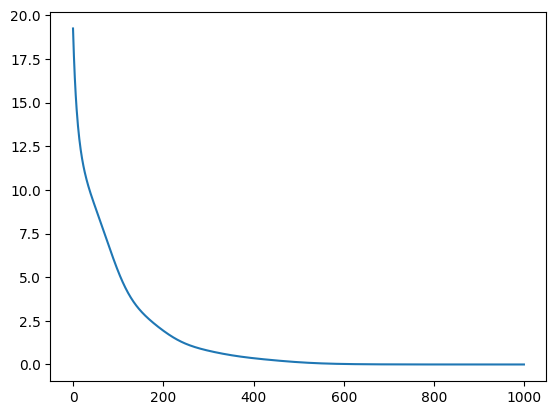

In [18]:
plt.plot(loss_history)